# BrushCue Example: Photo to Coloring Page

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/photo_to_coloring_page.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/photo-to-coloring-page

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


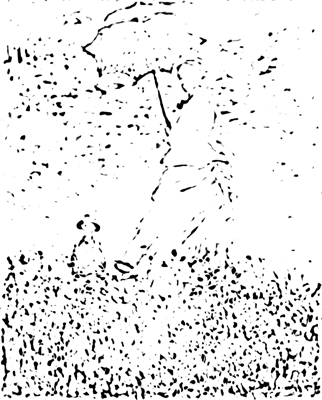

In [1]:
import io
from PIL import Image

import brushcue as bc

line_thickness = 3.0
detail = 0.45
input_image = bc.Composition.monet_women_with_parasol()
bounds = input_image.bounds()
reference_scale = (
    bc.Float.max(1.0, bc.Float.min(bounds.width(), bounds.height())) / 1000.0
)
sigma = bc.Float.max(0.5, (line_thickness * reference_scale))
pre_sigma = sigma * 0.5
padding = (pre_sigma * 4.0) + 2.0
padded_bounds = bc.Bounds2f.from_x_y_width_height(
    (bounds.min_x() - padding),
    (bounds.min_y() - padding),
    (bounds.width() + (padding * 2.0)),
    (bounds.height() + (padding * 2.0)),
)
padded = input_image.spacial_effect_shader(
    "return sample(clamp(position, image_bounds.xy + vec2f(0.5), image_bounds.zw - vec2f(0.5)));",
    "",
    padding,
    bc.Dictionary.create().add("image_bounds", bounds),
    bc.ColorRepresentation.srgb(),
).crop(padded_bounds)
smoothed = padded.gaussian_blur(pre_sigma).crop(bounds)
graph = smoothed.spacial_effect_shader(
    "let lo = image_bounds.xy + vec2f(0.5);\nlet hi = image_bounds.zw - vec2f(0.5);\nlet p = clamp(position, lo, hi);\nlet source = sample(p);\n// Per-channel difference of Gaussians: ink where any channel is darker than its\n// surroundings, so color boundaries get one line and thin dark strokes stay single.\nlet fine = blurred(p, sigma, lo, hi);\nlet wide = blurred(p, sigma * 2.5, lo, hi);\nlet difference = (wide - fine) / (wide + vec3f(0.3));\nlet edge = max(max(difference.r, difference.g), difference.b);\nlet threshold = mix(0.1, 0.012, detail);\nlet ink = smoothstep(threshold * 0.8, threshold * 1.2, edge);\nreturn vec4f(vec3f(1.0 - ink), source.a);",
    "// Gaussian blur over white paper, so transparent cutout edges become outlines.\nfn blurred(p: vec2f, s: f32, lo: vec2f, hi: vec2f) -> vec3f {\n    var total = vec3f(0.0);\n    var weights = 0.0;\n    for (var y = -6; y <= 6; y = y + 1) {\n        for (var x = -6; x <= 6; x = x + 1) {\n            let offset = vec2f(f32(x), f32(y));\n            let c = sample(clamp(p + offset * s * 0.5, lo, hi));\n            let weight = exp(-dot(offset, offset) * 0.125);\n            total += (clamp(c.rgb, vec3f(0.0), vec3f(1.0)) * c.a + vec3f(1.0 - c.a)) * weight;\n            weights += weight;\n        }\n    }\n    return total / weights;\n}",
    0.0,
    bc.Dictionary.create()
    .add("image_bounds", bounds)
    .add("sigma", sigma)
    .add("detail", detail),
    bc.ColorRepresentation.srgb(),
).crop(bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
